# Assignment

Implement the following Neural Architecture Search methods using this framework:

* Random Search
* Random Sample
* Bayesian Optimisation (put some thoughts how to represent information for the surrogate
model and how to define an acquition function)
* Succesive Halving
* An iteration-based learning curve method (see, e.g., the Power-law version of [1]).

Compare the performance of these methods using some reasonable standards (e.g., give
them the same budget) on various pre-computed datasets.

Setting up NAS system

In [24]:
import os
import csv
import random
import time
import json
import pickle

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

from nats_bench import create

SEARCH_SPACES = {'tss': 'NATS-Bench topology (TSS)'}
SEARCH_SPACE = 'tss'

FAST_MODE = True
BENCH_PATH = "data/NATS-tss-v1_0-3ffb9-simple"

DATASETS = ['cifar10', 'ImageNet16-120']


if not os.path.exists(BENCH_PATH):
    raise FileNotFoundError('Benchmark not found at {}. See section 1.'.format(BENCH_PATH))

api = create(BENCH_PATH, SEARCH_SPACE, fast_mode=FAST_MODE, verbose=False)

print('Search space: %s' % SEARCH_SPACES[SEARCH_SPACE])
print('Number of architectures:', len(api))

Search space: NATS-Bench topology (TSS)
Number of architectures: 15625


# Algorithms

## Random Search

In [2]:
def random_search(seed, hp_schedule, n_evals, dataset):
        records = []
        used_idx = set()
        rng = np.random.default_rng(seed)
        best_val_accuracy = -float("inf")
        best_test_accuracy = 0
        best_idx = None
        cumulative_cost = 0.0
    
    
        if dataset == 'cifar10':
            name = 'cifar10-valid'
        else:
            name = dataset

        for i in range(n_evals):
            idx = int(rng.integers(0, len(api)))

            # without replacement so keep doing it until its one that hasnt been tested before
            while idx in used_idx:
                idx = int(rng.integers(0, len(api)))

            used_idx.add(idx) 
            
            info = api.get_more_info(int(idx), name, hp=hp_schedule, is_random=False)
            val_accuracy = info["valid-accuracy"]
            test_accuracy = info["test-accuracy"]
            if best_val_accuracy < val_accuracy:
                best_val_accuracy = val_accuracy
                best_test_accuracy = test_accuracy
                best_idx = idx

            cumulative_cost += info["train-all-time"]
            
            records.append({
                "idx": int(idx),
                "best_idx": best_idx,
                "evaluation": i + 1,
                "val_accuracy": val_accuracy,
                "test_accuracy": test_accuracy,
                "best_val_accuracy": best_val_accuracy,
                "best_test_accuracy": best_test_accuracy,
                "training_cost": info["train-all-time"], # the cost of evaluating this particular architecture.
                "computation_cost": cumulative_cost,
                "epochs_trained": hp_schedule # amount of epochs trained
            })
            
        return records


## Random Sampling

In [3]:
def random_sampling(seed, hp_schedule, n_evals, dataset):
    """
    Random sampling draws a single random sample from the architecture space and returns it.

    is almost the same as random search thoo so maybe find out what is different

    """
    
    
    
    
    return 2

             
             

## Bayesian Optimisation

In [ ]:
from sklearn.preprocessing import OneHotEncoder
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import RBF, WhiteKernel


OPERATIONS = [
    "none",
    "skip_connect",
    "nor_conv_1x1",
    "nor_conv_3x3",
    "avg_pool_3x3"
]

def encode_structure(idx):
    arch_str = api.arch(idx)
    structure = []
    for dst, group in enumerate(arch_str.split('+'), start=1):
            items = group.strip().strip('|').split('|')
            for src, item in enumerate(items):
                structure.append((item.split('~')[0]))

    return structure


def UCB(mean, std, k):
    return mean + k * std

def bayesian_optimization(seed, hp_schedule, n_evals, dataset):
    # dataset init
    if dataset == 'cifar10':
        name = 'cifar10-valid'
    else:
        name = dataset

    records = []
    rng = np.random.default_rng(seed)
    best_val_accuracy = -float("inf")
    best_test_accuracy = 0
    best_idx = None
    cumulative_cost = 0.0

    
    encoder = OneHotEncoder(categories=[OPERATIONS] * 6, sparse_output=False) # categorie for each edge 
    encoder.fit([encode_structure(0)]) # init encoder

    # func to enocde the arcitecture
    def encode_architecture(idx):
        structure = encode_structure(idx)
        encoded = encoder.transform([structure])

        return encoded[0]

    all_architectures = np.array([
        encode_architecture(idx)
        for idx in range(len(api))
    ])


    #surgorate model init
    gp = GaussianProcessRegressor(
        kernel=RBF() + WhiteKernel(),
        normalize_y=True,
        random_state=seed
    )
    
    size = min(10, n_evals) # in case its more than the given value

    initial_indices = rng.choice(len(api), size=size, replace=False) # rn 10 but we can change this
    used_idx = set(int(idx) for idx in initial_indices)

    X = all_architectures[initial_indices]

    y = [] # result of valid accuray

    for i, indice in enumerate(initial_indices):
        info = api.get_more_info(int(indice), name, hp=hp_schedule, is_random=False)
        y.append(info["valid-accuracy"]) # needed for the algorithm

        # done for the results
        val_accuracy = info["valid-accuracy"]
        test_accuracy = info["test-accuracy"]
        if best_val_accuracy < val_accuracy:
            best_val_accuracy = val_accuracy
            best_test_accuracy = test_accuracy
            best_idx = int(indice)
        
        cumulative_cost += info["train-all-time"]
        records.append({
                "idx": int(indice),
                "best_idx": best_idx,
                "evaluation": i + 1,
                "val_accuracy": val_accuracy,
                "test_accuracy": test_accuracy,
                "best_val_accuracy": best_val_accuracy,
                "best_test_accuracy": best_test_accuracy,
                "training_cost": info["train-all-time"], # the cost of evaluating this particular architecture.
                "computation_cost": cumulative_cost,
                "epochs_trained": hp_schedule # amount of epochs trained
        })

    for i in range(n_evals - len(initial_indices)):
        gp.fit(X, y) # fitting on the surrogate model 

        # calc the rest of the indices
        candidate_indices = [
            idx for idx in range(len(api))
            if idx not in used_idx 
        ]

        X_candidates = all_architectures[candidate_indices]

        mean, std = gp.predict(X_candidates, return_std=True)
        ucb = UCB(mean, std, k=2)

        position = np.argmax(ucb) # need to be a full int
        candidate = candidate_indices[position]

        
        used_idx.add(candidate) 
        X = np.vstack([X, all_architectures[candidate]])
        info = api.get_more_info(int(candidate), name, hp=hp_schedule, is_random=False)
        y.append(info["valid-accuracy"])

        val_accuracy = info["valid-accuracy"]
        test_accuracy = info["test-accuracy"]
        if best_val_accuracy < val_accuracy:
            best_val_accuracy = val_accuracy
            best_test_accuracy = test_accuracy
            best_idx = candidate
        
        cumulative_cost += info["train-all-time"]
        records.append({
                "idx": candidate,
                "best_idx": best_idx,
                "evaluation": size + i + 1, # 10 + i + 1
                "val_accuracy": val_accuracy,
                "test_accuracy": test_accuracy,
                "best_val_accuracy": best_val_accuracy,
                "best_test_accuracy": best_test_accuracy,
                "training_cost": info["train-all-time"], # the cost of evaluating this particular architecture.
                "computation_cost": cumulative_cost,
                "epochs_trained": hp_schedule, # amount of epochs trained
        })

    return records






# print(encode_structure(3))
# print(encode_architecture(3))
# print(encode_architecture(3).shape)

## Successive Halving

In [5]:
# start with n_evals
# remove worst half each time
def succesive_halving():

    return 2

## Iteration-based learning curve method 

In [6]:
from scipy.optimize import curve_fit

# will implement the pow3 law (c-at^-a)

# Model: f(t) = c - a * t^(-alpha)
# t) training epoch
# f(t) predicited validation acccuracy
# c)  asymptot accuracy, the accuracy the curve approaches
# a) scale parameter, control how far acc is below c
# alpha) learning rate of the curve
# a, alpha and c are estimated by fitting the observed learning curve
# could use scipy.optimize.curve_fit


# -Partially train an architecture
# -store the learning curve
# =fit a parametric model
# -extraploate
# -use prediction to decide if promising

def pow3law(t, c, a, alpha):
    return c - a * t ** (-alpha)


def iterative_learning_curve(seed, hp_schedule, n_evals, dataset, step_size):
    # we have the problem tht only cifar10-valid has validation values before hp=200, 
    # the only solution to gets result on test_accuracy for them.
    if dataset == 'cifar10':
        name = 'cifar10-valid'
        curve_metric = 'valid-accuracy'
    else:
        name = dataset
        curve_metric = 'train-accuracy'
    
    results = []
    records = []
    rng = np.random.default_rng(seed)
    used_idx = set()
    best_val_accuracy = -float("inf")
    best_test_accuracy = 0
    best_idx = None
    cumulative_cost = 0.0

    for i in range(n_evals):
        previous_training_cost = 0.0
        # 1, get a random architecture        
        idx = rng.integers(0, len(api))
        # we dont want repeated indexs
        while idx in used_idx:
            idx = rng.integers(0, len(api))

        used_idx.add(idx)

        # init first found idx
        if i == 0: 
            info = api.get_more_info(int(idx), name, hp=hp_schedule, is_random=False)

            # since first entry, no if loop
            best_val_accuracy = info["valid-accuracy"]
            best_test_accuracy = info["test-accuracy"]
            best_curve_accuracy = info[curve_metric]
            best_idx = int(idx)

            cumulative_cost += info["train-all-time"] - previous_training_cost
            records.append({
                        "idx": int(idx),
                        "best_idx": best_idx,
                        "evaluation": i + 1,
                        "curve_metric": curve_metric,
                        "val_accuracy": best_val_accuracy,
                        "predicted_val_accuracy": None,
                        "test_accuracy": best_test_accuracy,
                        "best_val_accuracy": best_val_accuracy,
                        "best_test_accuracy": best_test_accuracy,
                        "training_cost": info["train-all-time"], # the cost of evaluating this particular architecture.
                        "computation_cost": cumulative_cost,
                        "epochs_trained": hp_schedule, # amount of epochs trained
                    })
            continue
            

        # 2. train it for a certain amount of steps
        step_count = min(step_size, hp_schedule) # since we dont want more step than hp_schedule
        while step_count <= hp_schedule:

            # part when we reach the hp_schedule
            # we dont predict anymore, we get info at hp_schedule
            if step_count == hp_schedule:
                info = api.get_more_info(int(idx), name, hp=hp_schedule, is_random=False)
                val_accuracy = info["valid-accuracy"]
                test_accuracy = info["test-accuracy"]
                if best_val_accuracy < val_accuracy:
                    best_val_accuracy = val_accuracy
                    best_test_accuracy = test_accuracy
                    best_curve_accuracy = info[curve_metric]
                    best_idx = int(idx)

                training_cost = info["train-all-time"] - previous_training_cost
                cumulative_cost += training_cost
                previous_training_cost = info["train-all-time"]


                records.append({
                            "idx": int(idx),
                            "best_idx": best_idx,
                            "evaluation": i + 1,
                            "val_accuracy": val_accuracy,
                            "predicted_val_accuracy": None,
                            "test_accuracy": test_accuracy,
                            "best_val_accuracy": best_val_accuracy,
                            "best_test_accuracy": best_test_accuracy,
                            "training_cost": training_cost, # the cost of evaluating this particular architecture.
                            "computation_cost": cumulative_cost,
                            "epochs_trained": hp_schedule, # amount of epochs trained
                        })
                break # stop the while loop



            # setting up the curve fit 
            X = [] # epoch
            y = [] # val acc 

            # filling up the data
            for epoch in range(step_count):
                results = api.get_more_info(int(idx), name, iepoch=epoch  ,hp=hp_schedule, is_random=False) # iepoch controlls at what step we end
                X.append(epoch + 1) # since we dont start at epoch 0
                y.append(results[curve_metric])

            # might need to change for cases where curve_fit doesnt work
            try:
                initial_c = min(100, max(y) + 5)
                params, _ = curve_fit(pow3law, 
                                    X, 
                                    y,
                                    p0=[initial_c, initial_c - y[0], 0.5],
                                    bounds=([0, 0, 0.001], [100, 200, 5]),
                                    maxfev=10000)
                # use params to get the calculated simulated_y
                simulated_y = pow3law(hp_schedule, *params)
            except (RuntimeError, ValueError): # in case it doesn work
                simulated_y = None 

            # Calculate additional training cost
            training_cost = results["train-all-time"] - previous_training_cost
            cumulative_cost += training_cost
            previous_training_cost = results["train-all-time"]

            val_accuracy = results.get("valid-accuracy")

            # test score only done on the hp_schedule version        
            records.append({
                    "idx": int(idx),
                    "best_idx": best_idx,
                    "evaluation": i + 1, 
                    "curve_metric": curve_metric,
                    "val_accuracy": val_accuracy,
                    "predicted_curve_accuracy": simulated_y,
                    "test_accuracy": None,
                    "best_val_accuracy": best_val_accuracy,
                    "best_test_accuracy": best_test_accuracy,
                    "training_cost": training_cost, # the cost of evaluating this particular architecture.
                    "computation_cost": cumulative_cost,
                    "epochs_trained": step_count, # amount of epochs trained
            })



            tolerance = 5  # percentage points
            min_epochs = 120
            if (
                step_count < min_epochs
                or simulated_y is None
                or simulated_y + tolerance > best_curve_accuracy
            ):
                step_count = min(step_count + step_size, hp_schedule)
                continue
            else:
                break

                # if it worse we drop it
                # but maybe still save info about this (like vall_acc that the current epoch has )


    return records





# Testing

In [7]:
# for now we do 3 seeds and 2 databases
DATASETS = ['cifar10', 'ImageNet16-120'] # different image sizes and data characterisitc
SEEDS = [20, 21, 22]
N_CONFIGS = 64 # amount of architectures evaluated # probabbly do a different one
HP_SCHEDULE = 200 # amount of epochs there is being trainted on

def experiment(function, **kwargs):
    all_results = {}

    for dataset in DATASETS:
        print(f"--- {dataset} ---")
        all_results[dataset] = {}

        for seed in SEEDS:
            print(f"--- {seed} ---")

            start = time.perf_counter()

            records = function(seed=seed,
                               hp_schedule=HP_SCHEDULE,
                               n_evals=N_CONFIGS,
                               dataset=dataset,
                               **kwargs
                               )

            runtime = time.perf_counter() - start 

            all_results[dataset][seed] = {
                "records": records,
                "runtime": runtime
            }

            final = records[-1]
            
            print(
                f"{dataset} | Seed {seed} | "
                f"Runtime: {runtime:.4f}s | "
                f"Records amount {len(records)} \n"
                f"Best idx: {final['best_idx']} | "
                f"Val: {final['best_val_accuracy']:.2f}% | "
                f"Test: {final['best_test_accuracy']:.2f}%"
            )

      
    # to have an idea how long the full experment was running
    total_runtime = sum(
        all_results[dataset][seed]["runtime"]
        for dataset in DATASETS
        for seed in SEEDS
    )
    print(f"\nTotal runtime: {total_runtime:.4f} seconds")
    print("#" * 42)

    return all_results



## running experiments

In [8]:
# os.makedirs("results", exist_ok=True)

print(f"--- Random Search ---")
rs_result = experiment(random_search)

with open("results/random_search_results.pkl", "wb") as f:
    pickle.dump(rs_result, f)

print(f"--- Bayesian Optimization ---")
ba_result = experiment(bayesian_optimization)

with open("results/bayesian_optimization_results.pkl", "wb") as f:
    pickle.dump(ba_result, f)

print(f"--- Iterative Learning Curve (Pow3) --- ")
step_size = 40 # a step count is necessary for this algorithm
ilc_result = experiment(iterative_learning_curve, step_size=step_size)
# some minor checks how it performed

print("\n--- Architectures reaching 200 epochs ---")

for dataset in DATASETS:
    print(f"\n--- {dataset} ---")

    for seed in SEEDS:
        records = ilc_result[dataset][seed]["records"]

        completed = len(set(
            r["idx"] for r in records
            if r["epochs_trained"] == HP_SCHEDULE
        ))

        stopped = N_CONFIGS - completed

        print(
            f"Seed {seed} | "
            f"Completed: {completed}/{N_CONFIGS} | "
            f"Stopped early: {stopped}/{N_CONFIGS}"
        )

with open("results/iterative_learning_curve.pkl", "wb") as f:
    pickle.dump(ilc_result, f)

# for dataset in DATASETS:
#     print(f"\n--- {dataset} ---")

#     for seed in SEEDS:
#         rs_cost = rs_result[dataset][seed]["records"][-1]["computation_cost"]
#         pow3_cost = ilc_result[dataset][seed]["records"][-1]["computation_cost"]

#         saved = (1 - pow3_cost / rs_cost) * 100

#         print(
#             f"Seed {seed} | "
#             f"RS: {rs_cost:.0f}s | "
#             f"POW3: {pow3_cost:.0f}s | "
#             f"Saved: {saved:.1f}%"
#         )



--- Random Search ---
--- cifar10 ---
--- 20 ---
cifar10 | Seed 20 | Runtime: 1.0381s | Records amount 64 
Best idx: 8610 | Val: 91.00% | Test: 90.47%
--- 21 ---
cifar10 | Seed 21 | Runtime: 0.9898s | Records amount 64 
Best idx: 1818 | Val: 90.80% | Test: 90.30%
--- 22 ---
cifar10 | Seed 22 | Runtime: 0.8490s | Records amount 64 
Best idx: 8002 | Val: 91.15% | Test: 91.19%
--- ImageNet16-120 ---
--- 20 ---
ImageNet16-120 | Seed 20 | Runtime: 0.0272s | Records amount 64 
Best idx: 6231 | Val: 44.60% | Test: 45.03%
--- 21 ---
ImageNet16-120 | Seed 21 | Runtime: 0.0242s | Records amount 64 
Best idx: 960 | Val: 44.73% | Test: 44.36%
--- 22 ---
ImageNet16-120 | Seed 22 | Runtime: 0.0230s | Records amount 64 
Best idx: 8002 | Val: 46.03% | Test: 45.57%

Total runtime: 2.9512 seconds
##########################################
--- Bayesian Optimization ---
--- cifar10 ---
--- 20 ---


c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarni

cifar10 | Seed 20 | Runtime: 524.3682s | Records amount 64 
Best idx: 9586 | Val: 91.34% | Test: 90.83%
--- 21 ---


c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarni

cifar10 | Seed 21 | Runtime: 501.7586s | Records amount 64 
Best idx: 1459 | Val: 91.45% | Test: 91.52%
--- 22 ---


c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarni

... (3 outputs left out)

c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarni

ImageNet16-120 | Seed 21 | Runtime: 492.5156s | Records amount 64 
Best idx: 3888 | Val: 46.68% | Test: 47.08%
--- 22 ---


c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarning: The optimal value found for dimension 0 of parameter k2__noise_level is close to the specified lower bound 1e-05. Decreasing the bound and calling fit again may find a better value.
  warnings.warn(
c:\Users\kayad\Universiteit\CS-AI-26-27\First-half-year\Automated Machine Learning\Assignments\A2\AutoML assignment2\.venv\Lib\site-packages\sklearn\gaussian_process\kernels.py:445: ConvergenceWarni

ImageNet16-120 | Seed 22 | Runtime: 494.0279s | Records amount 64 
Best idx: 3888 | Val: 46.68% | Test: 47.08%

Total runtime: 2972.0491 seconds
##########################################
--- Iterative Learning Curve (Pow3) --- 
--- cifar10 ---
--- 20 ---
cifar10 | Seed 20 | Runtime: 1.5280s | Records amount 200 
Best idx: 8610 | Val: 91.00% | Test: 90.47%
--- 21 ---
cifar10 | Seed 21 | Runtime: 1.5206s | Records amount 202 
Best idx: 1818 | Val: 90.80% | Test: 90.30%
--- 22 ---
cifar10 | Seed 22 | Runtime: 1.4340s | Records amount 198 
Best idx: 8002 | Val: 91.15% | Test: 91.19%
--- ImageNet16-120 ---
--- 20 ---
ImageNet16-120 | Seed 20 | Runtime: 2.2118s | Records amount 190 
Best idx: 13941 | Val: 39.82% | Test: 40.24%
--- 21 ---
ImageNet16-120 | Seed 21 | Runtime: 2.1293s | Records amount 190 
Best idx: 4709 | Val: 38.71% | Test: 38.79%
--- 22 ---
ImageNet16-120 | Seed 22 | Runtime: 2.1512s | Records amount 192 
Best idx: 258 | Val: 43.84% | Test: 43.73%

Total runtime: 10.9749 sec

# Loading the files

In [44]:
def load_results(filename):
    with open(f"results/{filename}", "rb") as file:
        return pickle.load(file)

print("--- Loading ---")    

rs_result = load_results("random_search_results.pkl")
ba_result = load_results("bayesian_optimization_results.pkl")
ilc_result = load_results("iterative_learning_curve.pkl")

all_results = {
    "Random Search": rs_result,
    "Bayesian Optimization": ba_result,
    "POW3": ilc_result
}

summary_rows = []
history_rows = []

for method, results in all_results.items():
    for dataset, seeds in results.items():
        for seed, run in seeds.items():

            records = run["records"]
            final = records[-1]

            summary_rows.append({
                "method": method,
                "dataset": dataset,
                "seed": seed,
                "val_accuracy": final["best_val_accuracy"],
                "test_accuracy": final["best_test_accuracy"],
                "computation_cost": final["computation_cost"],
                "runtime": run.get("runtime", np.nan),
                "architectures_considered": len(set(r["idx"] for r in records)),
                "architectures_completed": sum(
                    r["epochs_trained"] == HP_SCHEDULE
                    for r in records
                ) if all("epochs_trained" in r for r in records) else np.nan
            })

            for r in records:
                history_rows.append({
                    "method": method,
                    "dataset": dataset,
                    "seed": seed,
                    **r
                })

summary_df = pd.DataFrame(summary_rows)
history_df = pd.DataFrame(history_rows)

display(summary_df)
display(history_df.head())
# all_results
# ├── Random Search
# │   ├── cifar10
# │   │   ├── 20
# │   │   ├── 21
# │   │   └── 22
# │   └── ImageNet16-120
# ├── Bayesian Optimisation
# │   ├── cifar10
# │   └── ImageNet16-120
# └── POW3
#     ├── cifar10
#     └── ImageNet16-120

--- Loading ---


,method,dataset,seed,val_accuracy,test_accuracy,computation_cost,runtime,architectures_considered,architectures_completed
0,Random Search,cifar10,20,91.004000,90.470000,117086.573720,1.038064,64,64
1,Random Search,cifar10,21,90.800000,90.300000,116251.391371,0.989758,64,64
2,Random Search,cifar10,22,91.152000,91.190000,116073.358079,0.849021,64,64
3,Random Search,ImageNet16-120,20,44.600000,45.033333,710481.329333,0.027221,64,64
4,Random Search,ImageNet16-120,21,44.733333,44.355555,705413.442840,0.024176,64,64
5,Random Search,ImageNet16-120,22,46.033333,45.566667,704333.136822,0.022962,64,64
6,Bayesian Optimization,cifar10,20,91.344000,90.825000,143335.052288,524.368219,64,64
7,Bayesian Optimization,cifar10,21,91.448000,91.523333,145361.920818,501.758642,64,64
8,Bayesian Optimization,cifar10,22,91.553333,91.246667,146700.743850,488.025521,64,64
9,Bayesian Optimization,ImageNet16-120,20,46.183333,45.666667,927432.353728,471.353213,64,64


,method,dataset,seed,idx,best_idx,evaluation,val_accuracy,test_accuracy,best_val_accuracy,best_test_accuracy,training_cost,computation_cost,epochs_trained,curve_metric,predicted_val_accuracy,predicted_curve_accuracy
0,Random Search,cifar10,20,13941,13941,1,88.996000,89.040000,88.996000,89.04,2058.211303,2058.211303,200,NaN,NaN,NaN
1,Random Search,cifar10,20,4376,4376,2,89.726667,89.550000,89.726667,89.55,1888.231981,3946.443284,200,NaN,NaN,NaN
2,Random Search,cifar10,20,4088,4376,3,88.538000,88.125000,89.726667,89.55,1812.980882,5759.424166,200,NaN,NaN,NaN
3,Random Search,cifar10,20,7205,4376,4,80.554000,79.780000,89.726667,89.55,1504.622773,7264.046939,200,NaN,NaN,NaN
4,Random Search,cifar10,20,13984,4376,5,53.957333,54.146667,89.726667,89.55,1100.074617,8364.121556,200,NaN,NaN,NaN


                  method         dataset Validation-acc (%)  Test-acc (%)  \
0  Bayesian Optimization  ImageNet16-120       46.52 ± 0.29  46.61 ± 0.82   
1  Bayesian Optimization         cifar10       91.45 ± 0.10  91.20 ± 0.35   
2                   POW3  ImageNet16-120       40.79 ± 2.70  40.92 ± 2.54   
3                   POW3         cifar10       90.99 ± 0.18  90.65 ± 0.47   
4          Random Search  ImageNet16-120       45.12 ± 0.79  44.99 ± 0.61   
5          Random Search         cifar10       90.99 ± 0.18  90.65 ± 0.47   

    Cost (hours) Python runtime (minutes)  
0  256.94 ± 2.10              8.10 ± 0.21  
1   40.31 ± 0.47              8.41 ± 0.31  
2  119.34 ± 0.57              0.04 ± 0.00  
3   20.77 ± 0.27              0.02 ± 0.00  
4  196.32 ± 0.91              0.00 ± 0.00  
5   32.35 ± 0.15              0.02 ± 0.00  
Random Search
Bayesian Optimization
POW3


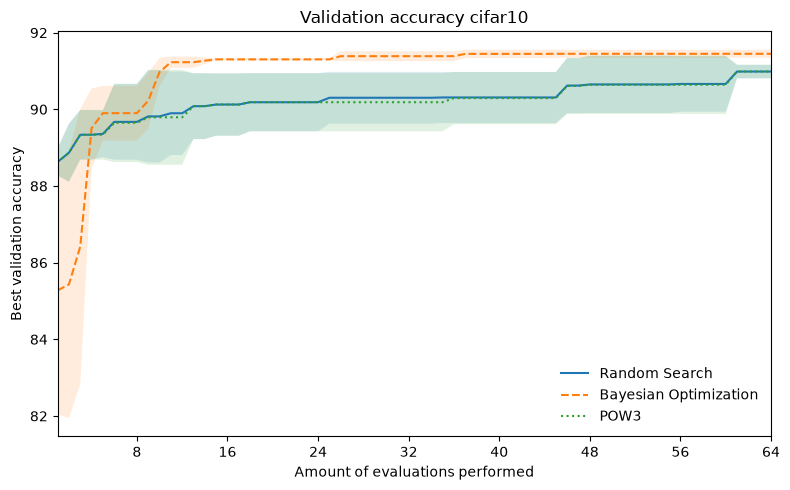

Random Search
Bayesian Optimization
POW3


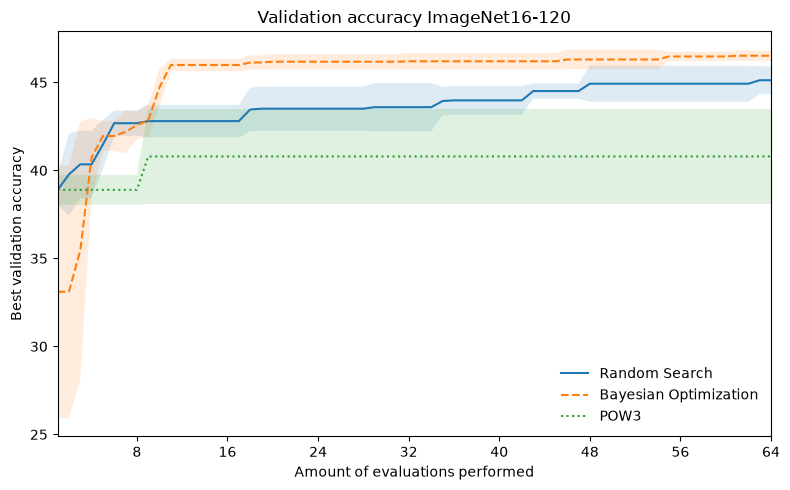

In [55]:
# table containing average over seeds
final_comparison = (
    summary_df
    .groupby(["method", "dataset"])
    .agg(
        mean_val=("val_accuracy", "mean"),
        std_val=("val_accuracy", "std"),
        mean_test=("test_accuracy", "mean"),
        std_test=("test_accuracy", "std"),
        mean_cost=("computation_cost", "mean"),
        std_cost=("computation_cost", "std"),
        mean_time=("runtime", "mean"),
        std_time=("runtime", "std")
    ).reset_index()
)

for col in ["mean_cost", "std_cost", "mean_time", "std_time"]: # minutes
    final_comparison[col] = (final_comparison[col] / 60) 

for col in ["mean_cost", "std_cost"]: # hours
    final_comparison[col] = (final_comparison[col] / 60) 

final_comparison["Validation-acc (%)"] = (
    final_comparison["mean_val"].map("{:.2f}".format)
 + " ± " +
 final_comparison["std_val"].map("{:.2f}".format)
)

final_comparison["Test-acc (%)"] = (
    final_comparison["mean_test"].map("{:.2f}".format)
 + " ± " +
 final_comparison["std_test"].map("{:.2f}".format)
)

final_comparison["Cost (hours)"] = (
    final_comparison["mean_cost"].map("{:.2f}".format)
 + " ± " +
 final_comparison["std_cost"].map("{:.2f}".format)
)

final_comparison["Python runtime (minutes)"] = (
    final_comparison["mean_time"].map("{:.2f}".format)
 + " ± " +
 final_comparison["std_time"].map("{:.2f}".format)
)

final_comparison_table = final_comparison[["method", "dataset", "Validation-acc (%)", "Test-acc (%)", "Cost (hours)", "Python runtime (minutes)" ]]

print(final_comparison_table)



# some of the historys have more than n_evals, that why we will take the last of each one
history_eval = (history_df
                .sort_values("computation_cost") # done since we want the last done to be defintly the on that was performed last
                .groupby(
                    ["method","dataset","seed", "evaluation" ],
                    as_index=False)
                ).last()

methods = ["Random Search", "Bayesian Optimization", "POW3"]

styles = {
    "Random Search": {"linestyle": "-", "marker": None},
    "Bayesian Optimization": {"linestyle": "--", "marker": None},
    "POW3": {"linestyle": ":", "marker": None}
} 

# creating figure for validation acc
for dataset in DATASETS:
    plt.figure(figsize=(8, 5))

    for method in methods:
        print(method)
        data = history_eval[
            (history_eval["dataset"] == dataset ) &
            (history_eval["method"] == method)
        ]

        stats = (
            data.groupby("evaluation")["best_val_accuracy"]
            .agg(["mean", "std"])
        )

        plt.plot(stats.index, stats["mean"], label=method, **styles[method])
        plt.fill_between(stats.index, stats["mean"] - stats["std"], stats["mean"] + stats["std"], alpha=0.14)

    plt.xlabel("Amount of evaluations performed")
    plt.ylabel("Best validation accuracy")
    plt.title(f"Validation accuracy {dataset}")
    plt.legend(
        loc="lower right",
        frameon=False
    )
    plt.xticks(np.arange(8, 65, 8))
    plt.xlim(1, 64)
    plt.tight_layout()
    plt.show()